In [1]:
import sys
import socket
import torch

print("Hostname:", socket.gethostname())
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))





import torch
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")

    try:
        torch.cuda.init()
        print("CUDA initialized successfully")
        print(torch.cuda.get_device_name(0))
    except Exception as e:
        print("CUDA initialization error:")
        print(repr(e))

    for warning in caught:
        print("WARNING:", warning.message)

Hostname: aladdin
Python: /cluster/miniforge3/envs/pkasso-env/bin/python
PyTorch: 2.14.1+cu126
PyTorch CUDA: 12.6
CUDA available: True
GPU count: 2
GPU: NVIDIA A40
CUDA initialized successfully
NVIDIA A40


In [2]:
from pkasso import protonate

name = "mymolecule"
smiles = r"OC(=O)C(c1ccc(O)cc1)CNCCN"
pH = 7.0

model = {
    "molgpka": {},
    "unipka": {
        "folds": (1,),
        "gpu": True,
    },
}

# Include microstates with probability of 20% compared to most probable microstate
# Select cutoff_export = 1. to only output the most likely microstate
cutoff_export = 0.2

# protonate accepts a smiles string or an rdkit Mol as input
smiles_out, mols_out = protonate(
    smiles,
    name=name,
    pH=pH,
    cutoff_export=cutoff_export,
    model=model)
print(smiles_out)

/cluster/miniforge3/envs/pkasso-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/cluster/miniforge3/envs/pkasso-env/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/cluster/miniforge3/envs/pkasso-env/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


('NCC[NH2+]CC(C(=O)[O-])c1ccc(O)cc1', '[NH3+]CCNCC(C(=O)[O-])c1ccc(O)cc1', '[NH3+]CC[NH2+]CC(C(=O)[O-])c1ccc(O)cc1')


In [27]:
from pkasso import protonate

batch_input = [
    "OC(=O)C(c1ccc(O)cc1)CNCCN",
    "C1CNCCN(C1)S(=O)(=O)C2=CC=CC3=C2C=CN=C3",
    "C1=C(NC=N1)CCN",
]

# Use a simple for loop to batch protonate

smiles_batch = []
mols_batch = []

for smiles in batch_input:
    smiles_out, mols_out = protonate(smiles, pH=7.2, cutoff_export=1.0)
    print(smiles_out)
    smiles_batch.append(smiles_out)
    mols_batch.append(mols_out)

('NCC[NH2+]CC(C(=O)[O-])c1ccc(O)cc1',)
('O=S(=O)(c1cccc2cnccc12)N1CCC[NH2+]CC1',)
('[NH3+]CCc1cnc[nH]1',)


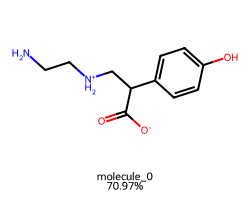

In [33]:
from pkasso.postprocess import draw_mols
from IPython.display import SVG, display

mols = mols_batch[0]

img = draw_mols(mols)

display(SVG(data=img) if isinstance(img, str) else img)

Macro-pKa values:
pKa1 | 1 --> 0 | 6.178
pKa2 | 2 --> 1 | 3.317
pKa3 | 0 --> -1 | 9.173
pKa4 | -1 --> -2 | 10.044


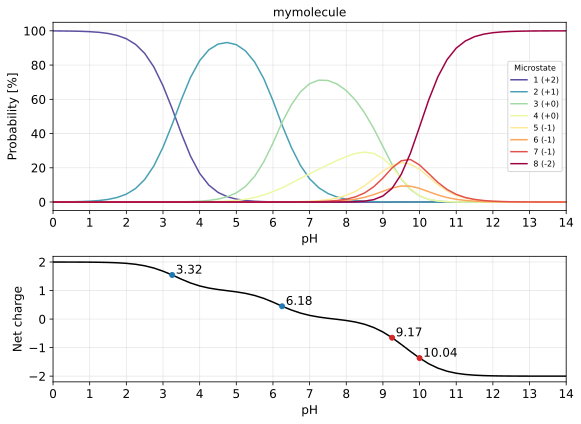

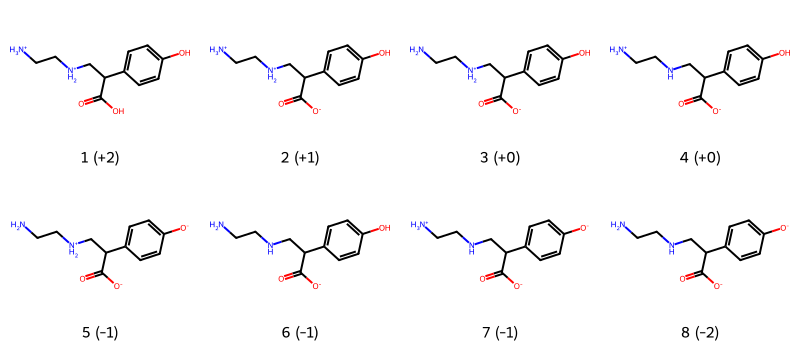

In [35]:
%config InlineBackend.figure_format = 'svg'

from pkasso import scan_pH
from IPython.display import display, SVG

smiles = r"OC(=O)C(c1ccc(O)cc1)CNCCN"
name = "mymolecule"

scan = scan_pH(
    smiles,
    name=name,
)

scan.print_macro_pkas()

def show_pkasso(obj):
    if isinstance(obj, str) and ("<svg" in obj[:500] or obj.lstrip().startswith("<?xml")):
        display(SVG(data=obj))
    else:
        display(obj)

show_pkasso(scan.plot_scan())
show_pkasso(scan.plot_mols())

In [37]:
from pkasso import scan_pH

model = {
    "molgpka": {},
    "unipka": {
        "folds": (1,),
        "gpu": True,
    },
}

scan_mixed = scan_pH(
    smiles,
    name="mymolecule_mixed",
    model=model,
)

scan_mixed.print_macro_pkas()

Macro-pKa values:
pKa1 | 1 --> 0 | 6.238 +/- 0.026
pKa2 | 2 --> 1 | 3.145 +/- 0.244
pKa3 | 0 --> -1 | 9.016 +/- 0.223
pKa4 | -1 --> -2 | 11.055 +/- 1.446


In [38]:
from pkasso import scan_pH

scan_unipka = scan_pH(
    smiles,
    name="unipka_only",
    model={
        "unipka": {
            "folds": (1,),
            "gpu": True,
        }
    },
)

scan_unipka.print_macro_pkas()

Macro-pKa values:
pKa1 | 1 --> 0 | 6.141
pKa2 | 2 --> 1 | 2.972
pKa3 | 0 --> -1 | 8.857
pKa4 | -1 --> -2 | 12.089
